### Finding the Cumulative Tip Coverage of Future Sequences Versus Minimum Mutation Distance

In this notebook, we analyze how well current spike sequences capture future ones by measuring cumulative tip coverage across defined future intervals. 

The analysis quantifies coverage as a function of the minimum mutation distance between present and future sequences, providing insight into the evolutionary proximity of predicted variants.



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [3]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH +"final_df.parquet"

final_df = pd.read_parquet(DATA_PATH)

id_to_seq = load_data(ROOT_PATH + "sequence_dict.parquet")

refSeq = getReference(ROOT_PATH + 'ref_spike_genome.fa')

Create Disjoint time interval slices

In [24]:
# --- Define cutoff date ---
cutoff_date = "2023-06-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
#disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']
disjoint_windows = ['6M_1', '6M_2']

# --- Perform slicing ---
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Combine slices into one dictionary ---
future_slices = disjoint_slices

# --- Summary output ---
# print(f"Cumulative slices: {list(cumulative_slices.keys())}")
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['6M_1', '6M_2']
Total future slices stored: 2


In [25]:
# --- Compute tip counts for current circulating sequences ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

min_tip_count = 5
current_seq_df = (
    current_seq_df[current_seq_df['Tip_Count'] >= min_tip_count]
    .reset_index(drop=True)
)

# --- Compute tip counts for each future window ---
future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

# --- Summary output ---
print(f"Computed current sequence DataFrame with {len(current_seq_df)} unique sequences")
print(f"Computed future sequence DataFrames for {len(future_seq_dfs)} windows")

Computed current sequence DataFrame with 1440 unique sequences
Computed future sequence DataFrames for 2 windows


### Writing distance results
We write one-row-per-id CSVs (`sample_ids_current.csv`, `sample_ids_future_<window>.csv`), then run the compiled `scripts/min_dist` binary to produce `dist_<window>.csv` in the same directory.

In [26]:
import os
import subprocess
from pathlib import Path

# --- Output directory (same layout as distance CSVs for this cutoff) ---
data_dir = os.path.join(ROOT_PATH.rstrip("/"), cutoff_date)
os.makedirs(data_dir, exist_ok=True)

# --- Unique Sequence_ID from prior block (current_seq_df / future_seq_dfs) ---
current_seq_ids = current_seq_df["Sequence_ID"].sort_values()
pd.DataFrame({"Sequence_ID": current_seq_ids}).to_csv(
    os.path.join(data_dir, "sample_ids_current.csv"),
    index=False,
)
print(f"Wrote {len(current_seq_ids)} unique current sequences")

for key in future_seq_dfs:
    fut_seq_ids = future_seq_dfs[key]["Sequence_ID"].sort_values()
    pd.DataFrame({"Sequence_ID": fut_seq_ids}).to_csv(
        os.path.join(data_dir, f"sample_ids_future_{key}.csv"),
        index=False,
    )
    print(f"Wrote {len(fut_seq_ids)} unique future {key} sequences")

# --- Run C++ min_dist (Hamming min distance vs current pool) ---
min_dist_bin = None
_p = Path.cwd().resolve()
for _ in range(12):
    _c = _p / "scripts" / "min_dist"
    if _c.is_file():
        min_dist_bin = _c
        break
    if _p.parent == _p:
        break
    _p = _p.parent
if min_dist_bin is None:
    min_dist_bin = Path.cwd() / "scripts" / "min_dist"
if not min_dist_bin.is_file():
    raise FileNotFoundError(
        f"min_dist not found at {min_dist_bin.resolve()}. From repo root: "
        "cmake -S scripts -B scripts/build && cmake --build scripts/build -j"
    )
parquet_path = os.path.join(ROOT_PATH, "sequence_dict.parquet")
cmd = [
    str(min_dist_bin.resolve()),
    "--parquet",
    parquet_path,
    "--data-dir",
    data_dir,
]
print("Running:", " ".join(cmd))
subprocess.run(cmd, check=True)


Wrote 1440 unique current sequences
Wrote 47254 unique future 6M_1 sequences
Wrote 26731 unique future 6M_2 sequences
Running: /home/pgangwar@AD.UCSD.EDU/FutureCoV/scripts/min_dist --parquet /data/pgangwar/vaccinescout/data/sequence_dict.parquet --data-dir /data/pgangwar/vaccinescout/data/2023-06-01
wrote "/data/pgangwar/vaccinescout/data/2023-06-01/dist_6M_2.csv" (26731 rows)
wrote "/data/pgangwar/vaccinescout/data/2023-06-01/dist_6M_1.csv" (47254 rows)


CompletedProcess(args=['/home/pgangwar@AD.UCSD.EDU/FutureCoV/scripts/min_dist', '--parquet', '/data/pgangwar/vaccinescout/data/sequence_dict.parquet', '--data-dir', '/data/pgangwar/vaccinescout/data/2023-06-01'], returncode=0)

### Reading distance results
Load `dist_<window>.csv` files from the same `data_dir` as the previous cell (output of `min_dist`: no header, columns Future_Sequence_ID, Current_Sequence_ID, Minimum_Distance).

In [27]:
import os
from glob import glob

data_dir = os.path.join(ROOT_PATH.rstrip("/"), cutoff_date)

csv_files = [os.path.join(data_dir, f"dist_{window}.csv") for window in disjoint_windows]

missing_files = [f for f in csv_files if not os.path.exists(f)]
if missing_files:
    raise FileNotFoundError(
        f"Missing expected files: {missing_files}. Run the previous cell first."
    )

future_dist_dfs = {}
columns = ["Future_Sequence_ID", "Current_Sequence_ID", "Minimum_Distance"]

for file in csv_files:
    key = os.path.basename(file).replace("dist_", "").replace(".csv", "")
    future_dist_dfs[key] = pd.read_csv(file, header=None, names=columns)

print(f"Loaded {len(future_dist_dfs)} future distance DataFrames from {data_dir}")
for key in sorted(future_dist_dfs.keys()):
    print(f" - {key}: {len(future_dist_dfs[key])} rows")

Loaded 2 future distance DataFrames from /data/pgangwar/vaccinescout/data/2023-06-01
 - 6M_1: 47254 rows
 - 6M_2: 26731 rows


### Computing all the results and compiling in cumulative form

In [28]:
# --- Dictionary to store cumulative coverage results for each future interval ---
results = {}

# --- Compute cumulative tip coverage by minimum mutation distance for each future window ---
for key in future_dist_dfs.keys():
    # DataFrame of distances for the current future window
    dist_df = future_dist_dfs[key]
    
    # DataFrame of tip counts for the same future window
    seq_df = future_seq_dfs[key]

    # --- Merge distance data with tip counts for future sequences ---
    merged = dist_df.merge(
        seq_df,
        left_on="Future_Sequence_ID",
        right_on="Sequence_ID"
    )

    # --- Aggregate tip counts by minimum mutation distance ---
    dist_counts = (
        merged.groupby("Minimum_Distance")["Tip_Count"]
        .sum()
        .reset_index()
        .sort_values("Minimum_Distance")
    )

    # --- Compute cumulative percentage of tips covered ---
    total = dist_counts["Tip_Count"].sum()
    dist_counts["Cumulative_%"] = dist_counts["Tip_Count"].cumsum() / total

    # --- Store only relevant columns in results dictionary ---
    results[key] = dist_counts[["Minimum_Distance", "Cumulative_%"]]

# --- Summary output ---
print(f"Computed cumulative tip coverage for {len(results)} future windows")
for key in results.keys():
    print(f" - {key}: {len(results[key])} distance bins")


Computed cumulative tip coverage for 2 future windows
 - 6M_1: 36 distance bins
 - 6M_2: 38 distance bins


### Plotting Cumulative Results

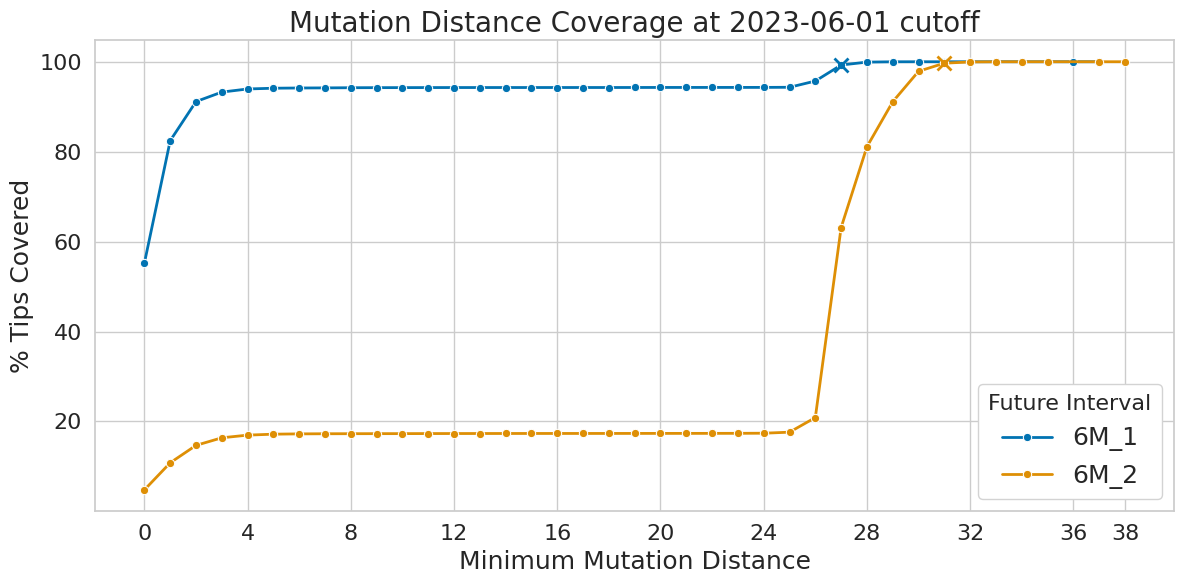

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Threshold for marking where cumulative coverage reaches 99% ---
threshold = 0.99  # stored as 0–1, convert to % later

# --- Mapping for nicer interval labels in the legend ---
legend_labels = {
    "3M_1": "0 - 3 months",
    "3M_2": "3 - 6 months",
    "3M_3": "6 - 9 months",
    "3M_4": "9 - 12 months"
}

# --- Prepare data for plotting ---
plot_data = []
marker_points = {}  # store x,y for first threshold exceed per slice
max_dist = 0        # track max distance for x-axis

for key, df in results.items():
    max_dist = max(max_dist, df["Minimum_Distance"].max())
    first_marker_set = False
    
    for _, row in df.iterrows():
        # --- Append row for plotting ---
        plot_data.append({
            "Distance": row["Minimum_Distance"],
            "Slice": legend_labels.get(key, key),
            "Cumulative %": row["Cumulative_%"] * 100  # convert fraction to %
        })
        
        # --- Record first point where threshold is exceeded ---
        if not first_marker_set and row["Cumulative_%"] >= threshold:
            marker_points[key] = (row["Minimum_Distance"], row["Cumulative_%"] * 100)
            first_marker_set = True

df_plot = pd.DataFrame(plot_data)

# --- Ensure all distances appear on x-axis ---
full_counts = list(range(0, max_dist + 1))
df_plot["Distance"] = pd.Categorical(
    df_plot["Distance"], categories=full_counts, ordered=True
)

# --- Plot cumulative coverage lines ---
plt.figure(figsize=(12, 6))
sns.set(style="whitegrid", palette="colorblind")

ax = sns.lineplot(
    data=df_plot,
    x="Distance",
    y="Cumulative %",
    hue="Slice",
    marker="o",
    linewidth=2
)

# --- Get consistent colors per slice ---
palette = sns.color_palette("colorblind", n_colors=df_plot["Slice"].nunique())
hue_order = df_plot["Slice"].unique()
color_map = dict(zip(hue_order, palette))

# --- Add 'x' markers at threshold exceed points ---
for key, (x, y) in marker_points.items():
    slice_label = legend_labels.get(key, key)
    ax.plot(x, y, "x", color=color_map[slice_label], markersize=10, markeredgewidth=2)

# --- Sparse x-axis labels to avoid clutter ---
tick_step = 4
sparse_ticks = list(range(0, max_dist + 1, tick_step))
if sparse_ticks[-1] != max_dist:
    sparse_ticks.append(max_dist)
ax.set_xticks(sparse_ticks)

# --- Axis labels, title, and legend styling ---
ax.set_title(f"Mutation Distance Coverage at {cutoff_date} cutoff", fontsize=20)
ax.set_ylabel("% Tips Covered", fontsize=18)
ax.set_xlabel("Minimum Mutation Distance", fontsize=18)
leg = plt.legend(
    title="Future Interval",
    fontsize=18,
    title_fontsize=16,
    frameon=True,
    facecolor="white",
    edgecolor="lightgray",
    framealpha=1.0,
)
leg.set_zorder(100)
ax.tick_params(axis="x", labelsize=16)
ax.tick_params(axis="y", labelsize=16)

# --- Adjust layout and display ---
plt.tight_layout()

plt.show()
